In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from db import engine
print("Connected")

Connected


In [2]:
ledger = pd.read_sql("SELECT * FROM cap.ledger_weekly ORDER BY team, week_start", engine, parse_dates=["week_start"])

num_cols = ["workload_hours", "paid_fte", "effective_fte", "supply_hours", "gap_hours", "fte_gap"]
ledger[num_cols] = ledger[num_cols].astype(float)

print("Rows:", len(ledger))
ledger.head()

Rows: 318


,week_start,team,requests,workload_hours,headcount,paid_fte,effective_fte,supply_hours,gap_hours,fte_gap
0,2024-10-21,Legal & Insurance,2286,877.2,32,31.5,31.50,921.4,44.2,1.51
1,2024-10-28,Legal & Insurance,2280,871.3,32,31.5,31.50,921.4,50.0,1.71
2,2024-11-04,Legal & Insurance,2391,915.2,32,31.5,31.50,921.4,6.1,0.21
3,2024-11-11,Legal & Insurance,2387,914.8,32,31.5,31.50,921.4,6.6,0.23
4,2024-11-18,Legal & Insurance,2315,884.2,33,32.5,31.75,928.7,44.5,1.52


In [3]:
def carry_backlog(gaps):
    backlog = 0.0
    result = []
    for gap in gaps:
        backlog = max(0.0, backlog - gap)
        result.append(round(backlog, 1))
    return result

print("Test with the example table:", carry_backlog([-10, -5, 20, 3]))

ledger["backlog_hours"] = 0.0
for team in ledger["team"].unique():
    rows = ledger["team"] == team
    ledger.loc[rows, "backlog_hours"] = carry_backlog(ledger.loc[rows, "gap_hours"])

ledger["backlog_days"] = (ledger["backlog_hours"] / (ledger["workload_hours"] / 5)).round(2)

latest = ledger[ledger["week_start"] == ledger["week_start"].max()]
latest[["team", "week_start", "fte_gap", "backlog_hours", "backlog_days"]]

Test with the example table: [10.0, 15.0, 0.0, 0.0]


,team,week_start,fte_gap,backlog_hours,backlog_days
105,Legal & Insurance,2026-10-26,-1.78,366.2,1.95
211,Patient Requests,2026-10-26,-0.42,197.8,1.41
317,Payer Requests,2026-10-26,-1.85,367.3,3.84


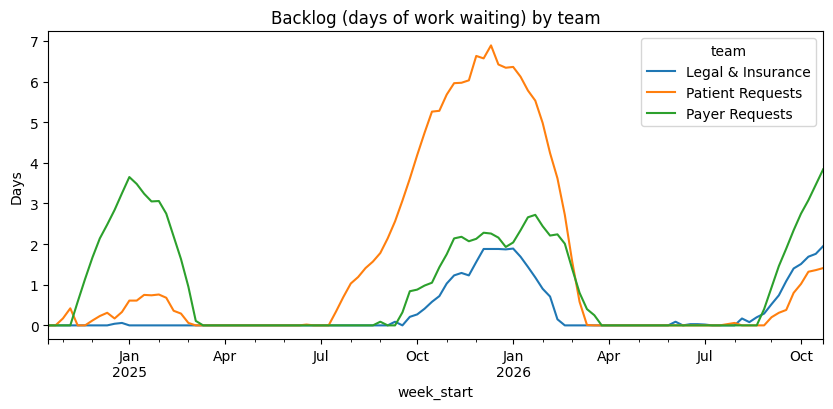

In [4]:
ledger.pivot(index="week_start", columns="team", values="backlog_days").plot(
    figsize=(10, 4), title="Backlog (days of work waiting) by team")
plt.ylabel("Days"); plt.show()

In [5]:
ledger.to_sql("ledger", engine, schema="cap", if_exists="replace", index=False)
print("Saved", len(ledger), "rows to cap.ledger")

Saved 318 rows to cap.ledger


In [6]:
weekly = pd.read_sql("""
    SELECT week_start, request_type,
           SUM(volume) AS volume,
           SUM(CASE WHEN channel = 'digital' THEN volume ELSE 0 END) * 1.0 / SUM(volume) AS digital_share,
           SUM(CASE WHEN channel = 'fax' THEN volume ELSE 0 END) * 1.0
             / NULLIF(SUM(CASE WHEN channel <> 'digital' THEN volume ELSE 0 END), 0) AS fax_share_of_paper
    FROM clean.requests
    GROUP BY week_start, request_type
    ORDER BY request_type, week_start
""", engine, parse_dates=["week_start"])

weekly[["volume", "digital_share", "fax_share_of_paper"]] = weekly[["volume", "digital_share", "fax_share_of_paper"]].astype(float)
weekly.tail()

,week_start,request_type,volume,digital_share,fax_share_of_paper
419,2026-09-28,payer,3289.0,0.599574,0.700076
420,2026-10-05,payer,3151.0,0.616312,0.699752
421,2026-10-12,payer,3200.0,0.593437,0.700231
422,2026-10-19,payer,3057.0,0.564933,0.700000
423,2026-10-26,payer,3270.0,0.579205,0.699855


In [7]:
def fit_predict(history, future_positions):
    t = np.arange(len(history))
    X = np.column_stack([np.ones(len(t)), t, np.sin(2*np.pi*t/52), np.cos(2*np.pi*t/52)])
    coefficients, *_ = np.linalg.lstsq(X, history, rcond=None)
    f = np.asarray(future_positions, dtype=float)
    X_future = np.column_stack([np.ones(len(f)), f, np.sin(2*np.pi*f/52), np.cos(2*np.pi*f/52)])
    return X_future @ coefficients

In [8]:
TEST_WEEKS = 26
results = []
for rtype, g in weekly.groupby("request_type"):
    y = g["volume"].values
    train_n = len(y) - TEST_WEEKS
    predicted = fit_predict(y[:train_n], np.arange(train_n, len(y)))
    for week, actual, pred in zip(g["week_start"].values[train_n:], y[train_n:], predicted):
        results.append({"week_start": week, "request_type": rtype, "actual": actual, "forecast": round(pred)})

backtest = pd.DataFrame(results)
backtest["abs_pct_error"] = (backtest["actual"] - backtest["forecast"]).abs() / backtest["actual"]
mape = round(backtest["abs_pct_error"].mean() * 100, 1)

print(f"Backtest MAPE: {mape}%")
print((backtest.groupby("request_type")["abs_pct_error"].mean() * 100).round(1))

Backtest MAPE: 3.4%
request_type
insurer    3.6
legal      3.0
patient    2.8
payer      4.3
Name: abs_pct_error, dtype: float64


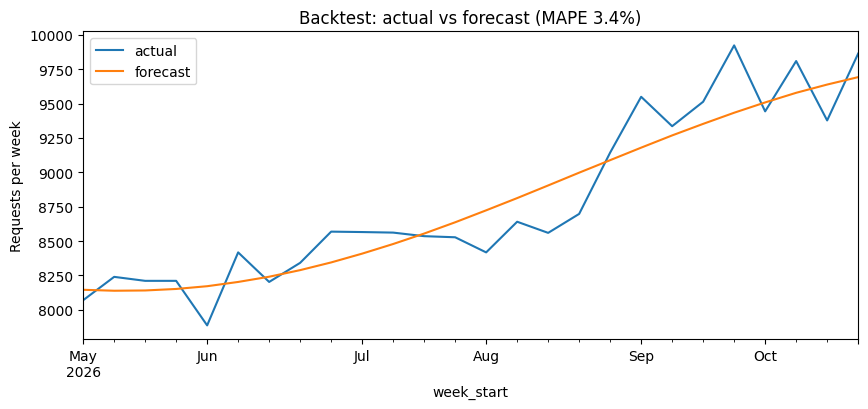

In [9]:
bt = backtest.groupby("week_start")[["actual", "forecast"]].sum()
bt.plot(figsize=(10, 4), title=f"Backtest: actual vs forecast (MAPE {mape}%)")
plt.ylabel("Requests per week"); plt.show()

In [10]:
HORIZON = 26
last_week = weekly["week_start"].max()
rows = []
for rtype, g in weekly.groupby("request_type"):
    n = len(g)
    future_t = np.arange(n, n + HORIZON)
    volume = fit_predict(g["volume"].values, future_t)
    slope, intercept = np.polyfit(np.arange(n), g["digital_share"].values, 1)
    digital = np.clip(intercept + slope * future_t, 0, 0.85)
    fax_share = g["fax_share_of_paper"].tail(13).mean()
    for i in range(HORIZON):
        rows.append({"week_start": last_week + pd.Timedelta(weeks=i + 1), "week_no": i + 1,
                     "request_type": rtype, "volume": round(volume[i]),
                     "digital_share": round(digital[i], 3), "fax_share_of_paper": round(fax_share, 3)})

forecast = pd.DataFrame(rows)
print("Forecast from", forecast["week_start"].min().date(), "to", forecast["week_start"].max().date())
forecast.head()

Forecast from 2026-11-02 to 2027-04-26


,week_start,week_no,request_type,volume,digital_share,fax_share_of_paper
0,2026-11-02,1,insurer,1155,0.606,0.7
1,2026-11-09,2,insurer,1160,0.608,0.7
2,2026-11-16,3,insurer,1163,0.610,0.7
3,2026-11-23,4,insurer,1166,0.613,0.7
4,2026-11-30,5,insurer,1168,0.615,0.7


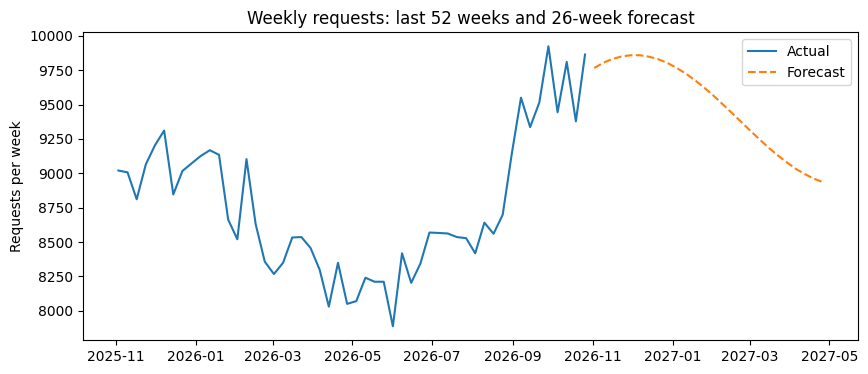

In [11]:
actual_total = weekly.groupby("week_start")["volume"].sum().tail(52)
forecast_total = forecast.groupby("week_start")["volume"].sum()
plt.figure(figsize=(10, 4))
plt.plot(actual_total.index, actual_total.values, label="Actual")
plt.plot(forecast_total.index, forecast_total.values, label="Forecast", linestyle="--")
plt.title("Weekly requests: last 52 weeks and 26-week forecast")
plt.ylabel("Requests per week"); plt.legend(); plt.show()

In [12]:
forecast.to_sql("forecast", engine, schema="cap", if_exists="replace", index=False)
backtest.to_sql("backtest", engine, schema="cap", if_exists="replace", index=False)
pd.DataFrame([{"run_time": pd.Timestamp.now(), "mape": mape}]).to_sql(
    "model_metrics", engine, schema="cap", if_exists="replace", index=False)

made_on = last_week.date()
with engine.begin() as conn:
    conn.execute(text("IF OBJECT_ID('cap.forecast_history', 'U') IS NOT NULL "
                      "DELETE FROM cap.forecast_history WHERE forecast_made_on = :d"), {"d": made_on})
forecast.assign(forecast_made_on=made_on).to_sql(
    "forecast_history", engine, schema="cap", if_exists="append", index=False)

print("Saved cap.forecast, cap.backtest, cap.model_metrics and cap.forecast_history")

Saved cap.forecast, cap.backtest, cap.model_metrics and cap.forecast_history
